# Charts

Charts the 12-month change in premiums against a combined claim cost index, and the fitted trend rates for each series

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

conn = sqlite3.connect("../data/trend.db")

In [2]:
#load the 12-month changes, our SQL code from notebook 2
yoy_query = """
SELECT series, date, yoy_change
FROM yoy_changes
WHERE date >= '2018-01-01'
"""
yoy = pd.read_sql(yoy_query, conn)
yoy["date"] = pd.to_datetime(yoy["date"])
yoy.head()

,series,date,yoy_change
0,insurance,2018-01-01,0.085105
1,insurance,2018-02-01,0.096262
2,insurance,2018-03-01,0.087265
3,insurance,2018-04-01,0.089747
4,insurance,2018-05-01,0.083361


In [3]:
#build a monthly claim cost index
weights = {"repair": 0.31, "parts": 0.27, "used_cars": 0.17, "medical": 0.25}

#one column per series, one row per month
wide = yoy.pivot(index="date", columns="series", values="yoy_change")

#weighted 12-month change in claim costs, only when all four series have a value
wide["severity"] = (wide[list(weights)] * pd.Series(weights)).sum(axis=1, min_count=4)
wide[["severity", "insurance"]].tail()

series,severity,insurance
date,,
2026-06-01,0.028473,-0.041101
2026-07-01,0.025560,-0.044577
2026-08-01,0.018727,-0.051277
2026-09-01,0.021471,-0.049832
2026-10-01,NaN,NaN


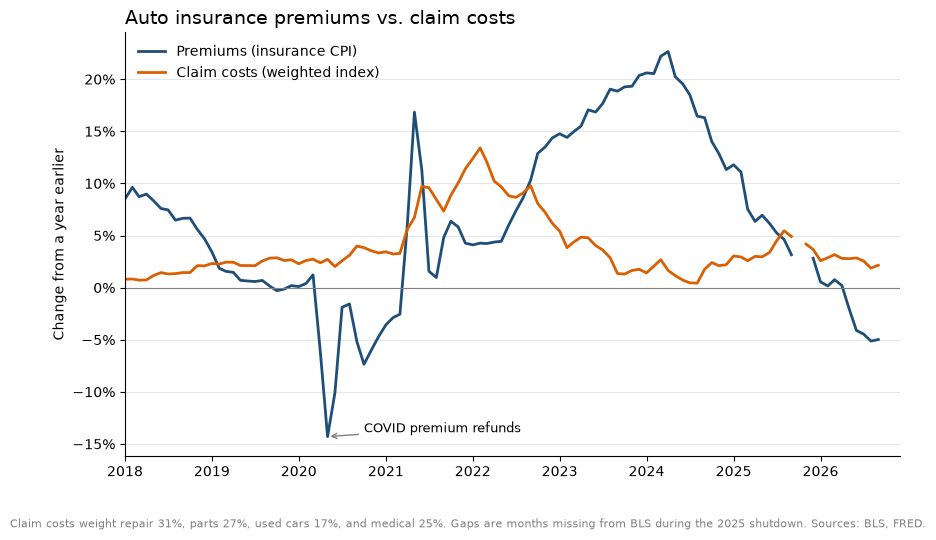

In [4]:
#plotting time
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(wide.index, wide["insurance"], color="#1f4e79", linewidth=2, label="Premiums (insurance CPI)")
ax.plot(wide.index, wide["severity"], color="#d95f02", linewidth=2, label="Claim costs (weighted index)")
ax.axhline(0, color="grey", linewidth=0.8)

ax.annotate("COVID premium refunds", xy=(pd.Timestamp("2020-05-01"), -0.143),
            xytext=(pd.Timestamp("2020-10-01"), -0.135), fontsize=9, va="center",
            arrowprops=dict(arrowstyle="->", color="grey"))

ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(pd.Timestamp("2018-01-01"), pd.Timestamp("2026-12-01"))
ax.set_title("Auto insurance premiums vs. claim costs", loc="left", fontsize=14)
ax.set_ylabel("Change from a year earlier")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.01, -0.02, "Claim costs weight repair 31%, parts 27%, used cars 17%, and medical 25%. "
         "Gaps are months missing from BLS during the 2025 shutdown. Sources: BLS, FRED.",
         fontsize=8, color="grey")

fig.savefig("../images/premium_vs_severity.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
#load the trend rates from notebook 2
trend_query = """
SELECT series, trend_3yr, trend_5yr
FROM trend_rates
"""
rates = pd.read_sql(trend_query, conn)
rates

,series,trend_3yr,trend_5yr
0,insurance,0.028132,0.105816
1,medical,0.026799,0.022663
2,miles_traveled,0.009991,0.011263
3,parts,0.021733,0.019424
4,repair,0.061314,0.074366
5,used_cars,-0.003687,-0.031108


In [6]:
#add the weighted claim cost trend from notebook 2
sev = pd.read_sql("SELECT * FROM severity_vs_premium", conn)
claim_costs = {"series": "claim_costs",
               "trend_3yr": sev["severity_trend"][0],
               "trend_5yr": sev["severity_trend"][1]}
rates = pd.concat([rates, pd.DataFrame([claim_costs])], ignore_index=True)
rates

,series,trend_3yr,trend_5yr
0,insurance,0.028132,0.105816
1,medical,0.026799,0.022663
2,miles_traveled,0.009991,0.011263
3,parts,0.021733,0.019424
4,repair,0.061314,0.074366
5,used_cars,-0.003687,-0.031108
6,claim_costs,0.030948,0.028675


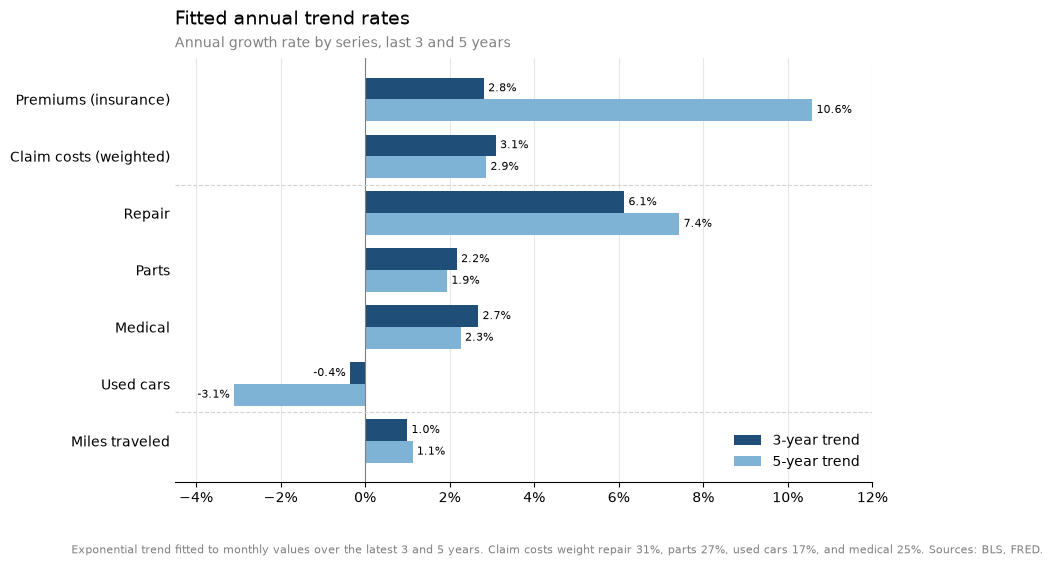

In [7]:
import numpy as np

labels = {"insurance": "Premiums (insurance)",
          "claim_costs": "Claim costs (weighted)",
          "repair": "Repair",
          "parts": "Parts",
          "medical": "Medical",
          "used_cars": "Used cars",
          "miles_traveled": "Miles traveled"}

#premiums and claim costs on top, then the parts of claim costs, then exposure
plot_rates = rates.set_index("series").loc[list(labels)]
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(plot_rates))
h = 0.38

bars3 = ax.barh(y - h/2, plot_rates["trend_3yr"], height=h, color="#1f4e79", label="3-year trend")
bars5 = ax.barh(y + h/2, plot_rates["trend_5yr"], height=h, color="#7fb3d5", label="5-year trend")

ax.bar_label(bars3, labels=[f"{v:.1%}" for v in plot_rates["trend_3yr"]], padding=3, fontsize=8)
ax.bar_label(bars5, labels=[f"{v:.1%}" for v in plot_rates["trend_5yr"]], padding=3, fontsize=8)

ax.set_yticks(y, [labels[s] for s in plot_rates.index])
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.axvline(0, color="grey", linewidth=0.8)

#divider lines between premiums vs. claim costs, the cost components, and exposure
for line in [1.5, 5.5]:
    ax.axhline(line, color="lightgrey", linewidth=0.8, linestyle="--")

ax.set_xlim(-0.045, 0.12)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.text(0, 1.08, "Fitted annual trend rates", transform=ax.transAxes, fontsize=14)
ax.set_title("Annual growth rate by series, last 3 and 5 years", loc="left", fontsize=10, color="grey", pad=8)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right", "left"]].set_visible(False)

fig.text(0.01, -0.02, "Exponential trend fitted to monthly values over the latest 3 and 5 years. "
         "Claim costs weight repair 31%, parts 27%, used cars 17%, and medical 25%. Sources: BLS, FRED.",
         fontsize=8, color="grey")

fig.savefig("../images/trend_rates.png", dpi=200, bbox_inches="tight")
plt.show()
conn.close()

The first chart shows the full cycle: claim costs rose first in 2021–22, premiums caught up and overshot by 2024, and premiums have now fallen below claim cost growth. The second shows why the 3-year window matters for projecting forward: the cost trends are similar over 3 and 5 years, while the 5-year premium trend is inflated by the 2023–24 catch-up.